# BIOT 6900 · Module 10 Assignment — Medical Imaging AI: Build It, Then Break It
**Nicholas Adrogue** · Computational Lab 10 · Fall 2026

Tumour (colorectal adenocarcinoma epithelium) vs. normal colon mucosa on PathMNIST, using a fine-tuned DenseNet121. Confounder: a synthetic out-of-focus (Gaussian blur) patch.

*Code comments marked `NEW:` are not in the Notebook 2 template; comments marked `CHANGED:` describe how a Notebook 2 function was modified. Unmarked code is reused from Notebook 2 as-is.*

## 0 · Setup

In [1]:
import os, zlib, numpy as np, pandas as pd, matplotlib.pyplot as plt   # CHANGED: added pandas (result tables) and zlib (per-tile blur position)
import torch, torch.nn as nn, torch.nn.functional as Fnn

import monai
from monai.utils import set_determinism
from monai.networks.nets import DenseNet121
from monai.visualize import GradCAM
from torch.utils.data import Dataset, DataLoader
from monai.transforms import Compose, EnsureChannelFirst, ScaleIntensity, Resize, EnsureType, GaussianSmooth  # CHANGED: added GaussianSmooth (blur confounder)
from sklearn.metrics import confusion_matrix
# CHANGED: all imports gathered here; Notebook 2 spread them across sections.

print("MONAI:", monai.__version__, "| torch:", torch.__version__)

SEED = 0
set_determinism(seed=SEED)
device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available()
                      else "cpu")
print("device:", device)

MONAI: 1.6.1 | torch: 2.15.0
device: mps


## 1 · Data

In [2]:
# CHANGED: loads only the prepared subset file. Notebook 2's PathMNIST download fallback
# and its subsample() helper were removed, since the .npz is required by the assignment.
IMG_SIZE = 128
SUBSET_FILE = "./data/pathmnist_tumour_vs_normal_subset.npz"
class_names = ["normal", "tumour"]   # 0 = normal colon mucosa, 1 = colorectal adenocarcinoma epithelium

d = np.load(SUBSET_FILE)
xtr_s, ytr_s, xva_s, yva_s, xte_s, yte_s = (d[k] for k in ["xtr", "ytr", "xva", "yva", "xte", "yte"])
print(f"tiles are {xtr_s.shape[1]} px (resized to {IMG_SIZE} px)")
print(f"train {len(ytr_s)} | val {len(yva_s)} | test {len(yte_s)}")
# NEW: per-split class counts, to confirm the subset is balanced.
for name, y in [("train", ytr_s), ("val", yva_s), ("test", yte_s)]:
    print(f"  {name}: normal {(y == 0).sum()} | tumour {(y == 1).sum()}")

tiles are 64 px (resized to 128 px)
train 600 | val 400 | test 600
  train: normal 300 | tumour 300
  val: normal 200 | tumour 200
  test: normal 300 | tumour 300


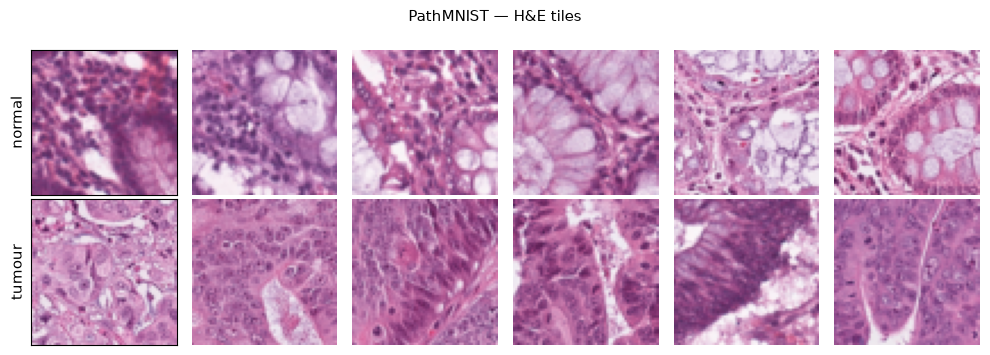

In [3]:
fig, axes = plt.subplots(2, 6, figsize=(10, 3.6))
for r, c in enumerate((0, 1)):
    ci = np.where(ytr_s == c)[0][:6]
    for k, j in enumerate(ci):
        axes[r, k].imshow(xtr_s[j]); axes[r, k].axis("off")
    axes[r, 0].set_ylabel(class_names[c], fontsize=11, rotation=90)
    axes[r, 0].axis("on"); axes[r, 0].set_xticks([]); axes[r, 0].set_yticks([])
plt.suptitle("PathMNIST — H&E tiles", fontsize=11); plt.tight_layout(); plt.show()

## 2 · Preprocessing, dataset, and training utilities

In [4]:
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

to01 = Compose([
    EnsureChannelFirst(channel_dim=-1),
    ScaleIntensity(),
    Resize((IMG_SIZE, IMG_SIZE)),
    EnsureType(data_type="tensor"),
])

def normalize(x01):
    return (x01 - IMAGENET_MEAN) / IMAGENET_STD

# CHANGED: Notebook 2's TileDataset always called add_ink_mark(). This version takes the
# artifact as an argument (artifact_fn), so any confounder can be plugged in, and so the
# same dataset can add the artifact to either class (used for the flip test in Part D).
class TileDataset(Dataset):
    def __init__(self, imgs, labels, artifact_fn=None, artifact_label=None):
        self.imgs, self.labels = imgs, labels
        self.artifact_fn, self.artifact_label = artifact_fn, artifact_label
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        x01 = to01(self.imgs[i])
        if self.artifact_fn is not None and self.labels[i] == self.artifact_label:
            x01 = self.artifact_fn(x01)
        return normalize(x01), int(self.labels[i])

# CHANGED: passes artifact_fn through to TileDataset (Notebook 2 only passed artifact_label).
def make_loaders(artifact_fn=None, artifact_label=None, bs=32):
    tr = DataLoader(TileDataset(xtr_s, ytr_s, artifact_fn, artifact_label), batch_size=bs, shuffle=True)
    va = DataLoader(TileDataset(xva_s, yva_s, artifact_fn, artifact_label), batch_size=64)
    return tr, va

# CHANGED: pretrained now defaults to True (only transfer models are trained here).
def build_densenet(pretrained=True):
    return DenseNet121(spatial_dims=2, in_channels=3, out_channels=2,
                       pretrained=pretrained).to(device)

def run_epoch(net, loader, opt=None):
    train = opt is not None
    net.train() if train else net.eval()
    crit = nn.CrossEntropyLoss(); tot = cor = 0; ls = 0.0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = net(x); loss = crit(out, y)
            if train: opt.zero_grad(); loss.backward(); opt.step()
            ls += loss.item() * x.size(0); cor += (out.argmax(1) == y).sum().item(); tot += x.size(0)
    return ls / tot, cor / tot

def train(net, tr_loader, va_loader, epochs=3, lr=1e-4):
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    for ep in range(1, epochs + 1):
        trl, tra = run_epoch(net, tr_loader, opt)
        val, vaa = run_epoch(net, va_loader)
        # CHANGED: also prints train/val loss (Notebook 2 printed accuracy only).
        print(f"  epoch {ep}: train loss {trl:.3f} acc {tra:.3f} | val loss {val:.3f} acc {vaa:.3f}")
    return net

# CHANGED: replaces Notebook 2's evaluate(). Returns predictions only (accuracy is computed
# where needed) and can add the artifact to one class, so the reliance and flip tests
# below reuse it in one batched pass instead of looping tile by tile.
def predict(net, imgs, labels, artifact_fn=None, artifact_label=None):
    net.eval(); preds = []
    loader = DataLoader(TileDataset(imgs, labels, artifact_fn, artifact_label), batch_size=64)
    with torch.no_grad():
        for x, _ in loader:
            preds.append(net(x.to(device)).argmax(1).cpu().numpy())
    return np.concatenate(preds)

# CHANGED: Notebook 2's inline confusion-matrix plot, wrapped in a function.
def plot_cm(labels, preds, title):
    cm = confusion_matrix(labels, preds)
    fig, ax = plt.subplots(figsize=(3.8, 3.4)); ax.imshow(cm, cmap="Reds")
    ax.set_xticks([0, 1]); ax.set_xticklabels(class_names); ax.set_yticks([0, 1]); ax.set_yticklabels(class_names)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.title(title); plt.tight_layout(); plt.show()

_x01 = to01(xtr_s[0]); _xn = normalize(_x01)
print("display [0,1]:", tuple(_x01.shape), float(_x01.min()), float(_x01.max()))
print("model input  :", tuple(_xn.shape), f"mean~{float(_xn.mean()):.2f}")

display [0,1]: (3, 128, 128) 0.0 1.0
model input  : (3, 128, 128) mean~0.06


## 3 · Interrogation tools: Grad-CAM and occlusion

In [5]:
TARGET_LAYER = "class_layers.relu"

def minmax_keep_high(x):
    flat = x.flatten(start_dim=1)
    lo = flat.min(dim=1)[0].view(-1, *([1] * (x.dim() - 1)))
    hi = flat.max(dim=1)[0].view(-1, *([1] * (x.dim() - 1)))
    return (x - lo) / (hi - lo + 1e-8)

def make_cam(net):
    return GradCAM(nn_module=net, target_layers=TARGET_LAYER, postprocessing=minmax_keep_high)

# NEW: predicted class + class probabilities for one tile (replaces the inline
# net(...).argmax() calls scattered through Notebook 2).
def predict_one(net, x01):
    net.eval()
    with torch.no_grad():
        p = Fnn.softmax(net(normalize(x01).unsqueeze(0).to(device)), 1)[0].cpu().numpy()
    return int(p.argmax()), p

# NEW: Grad-CAM map for one tile and a chosen class, returned as a numpy array.
# Factored out of Notebook 2's show_cam()/cam_on_array(), which computed and plotted together.
def gradcam_map(net, cam_obj, x01, class_idx):
    xin = normalize(x01).unsqueeze(0).to(device)
    return cam_obj(x=xin, class_idx=class_idx).squeeze().detach().cpu().numpy()

def occlusion_map(net, x01, target, patch=20, stride=16, baseline=0.0):
    net.eval()
    xin = normalize(x01).unsqueeze(0).to(device)
    with torch.no_grad():
        base = Fnn.softmax(net(xin), 1)[0, target].item()
    H, W = IMG_SIZE, IMG_SIZE
    heat = np.zeros((H, W)); cnt = np.zeros((H, W))
    for i in range(0, H - patch + 1, stride):
        for j in range(0, W - patch + 1, stride):
            x2 = xin.clone(); x2[..., i:i+patch, j:j+patch] = baseline
            with torch.no_grad():
                p = Fnn.softmax(net(x2), 1)[0, target].item()
            heat[i:i+patch, j:j+patch] += (base - p); cnt[i:i+patch, j:j+patch] += 1
    return heat / np.maximum(cnt, 1)

# NEW: puts a number on checklist point 3 ("does occlusion agree with Grad-CAM?").
# Pearson correlation between the two maps; ~1 = same regions, ~0 = unrelated.
def map_agreement(gmap, omap):
    o = np.clip(omap, 0, None)                 # keep only evidence FOR the class
    if o.std() < 1e-8 or gmap.std() < 1e-8:
        return float("nan")
    return float(np.corrcoef(gmap.ravel(), o.ravel())[0, 1])

# NEW: Part B probe figure. Notebook 2 only ran Grad-CAM on tumour tiles; this runs
# Grad-CAM AND occlusion on any list of tiles (tumour and normal), one column per tile,
# and returns a table of prediction, confidence, and Grad-CAM/occlusion agreement.
def probe_panel(net, cam_obj, x01_list, titles, suptitle):
    k = len(x01_list); rows = []
    fig, ax = plt.subplots(3, k, figsize=(2.4 * k, 7.2))
    ax = np.array(ax).reshape(3, k)
    for col, (x01, t) in enumerate(zip(x01_list, titles)):
        pr, p = predict_one(net, x01)
        g = gradcam_map(net, cam_obj, x01, pr)
        o = occlusion_map(net, x01, pr)
        disp = x01.permute(1, 2, 0).cpu().numpy()
        ax[0, col].imshow(disp); ax[0, col].set_title(f"{t}\npred {class_names[pr]} ({p[pr]:.2f})", fontsize=8)
        ax[1, col].imshow(disp); ax[1, col].imshow(g, cmap="jet", alpha=0.45, vmin=0, vmax=1)
        ax[2, col].imshow(disp); ax[2, col].imshow(np.clip(o, 0, None), cmap="jet", alpha=0.45)
        for r in range(3): ax[r, col].axis("off")
        rows.append({"tile": t, "pred": class_names[pr], "p(pred)": round(float(p[pr]), 3),
                     "gradcam~occlusion r": round(map_agreement(g, o), 2)})
    ax[1, 0].text(-8, IMG_SIZE / 2, "Grad-CAM", rotation=90, va="center", ha="right", fontsize=9)
    ax[2, 0].text(-8, IMG_SIZE / 2, "occlusion", rotation=90, va="center", ha="right", fontsize=9)
    plt.suptitle(suptitle, fontsize=10); plt.tight_layout(); plt.show()
    return pd.DataFrame(rows)

## Part A · Clean model

In [6]:
# CHANGED: Notebook 2 trained a from-scratch DenseNet first for comparison; that run is removed.
# This is Notebook 2's transfer model (same epochs, lr, and seed).
EPOCHS = 3
set_determinism(seed=SEED)
tr_loader, va_loader = make_loaders()
print("Clean model — pretrained DenseNet121 (ImageNet), fine-tuned:")
model = train(build_densenet(pretrained=True), tr_loader, va_loader, epochs=EPOCHS)

Clean model — pretrained DenseNet121 (ImageNet), fine-tuned:
  epoch 1: train loss 0.354 acc 0.850 | val loss 0.160 acc 0.955
  epoch 2: train loss 0.062 acc 0.990 | val loss 0.092 acc 0.965
  epoch 3: train loss 0.022 acc 1.000 | val loss 0.080 acc 0.968


clean model  validation accuracy: 0.968
clean model  test accuracy      : 0.948
clean model  test tumour recall : 0.937
clean model  test normal recall : 0.960


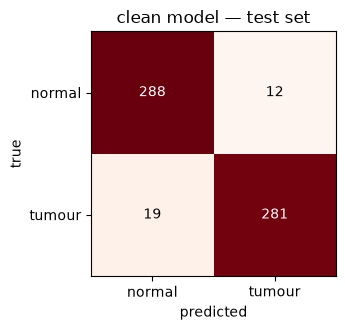

In [7]:
# NEW: explicit final validation accuracy and per-class recall (Notebook 2 reported
# test accuracy only, plus val accuracy in the per-epoch training log).
val_pred = predict(model, xva_s, yva_s)
test_pred = predict(model, xte_s, yte_s)
clean_val_acc = (val_pred == yva_s).mean()
clean_test_acc = (test_pred == yte_s).mean()
print(f"clean model  validation accuracy: {clean_val_acc:.3f}")
print(f"clean model  test accuracy      : {clean_test_acc:.3f}")
print(f"clean model  test tumour recall : {(test_pred[yte_s == 1] == 1).mean():.3f}")
print(f"clean model  test normal recall : {(test_pred[yte_s == 0] == 0).mean():.3f}")
plot_cm(yte_s, test_pred, "clean model — test set")

## Part B · Probing the clean model

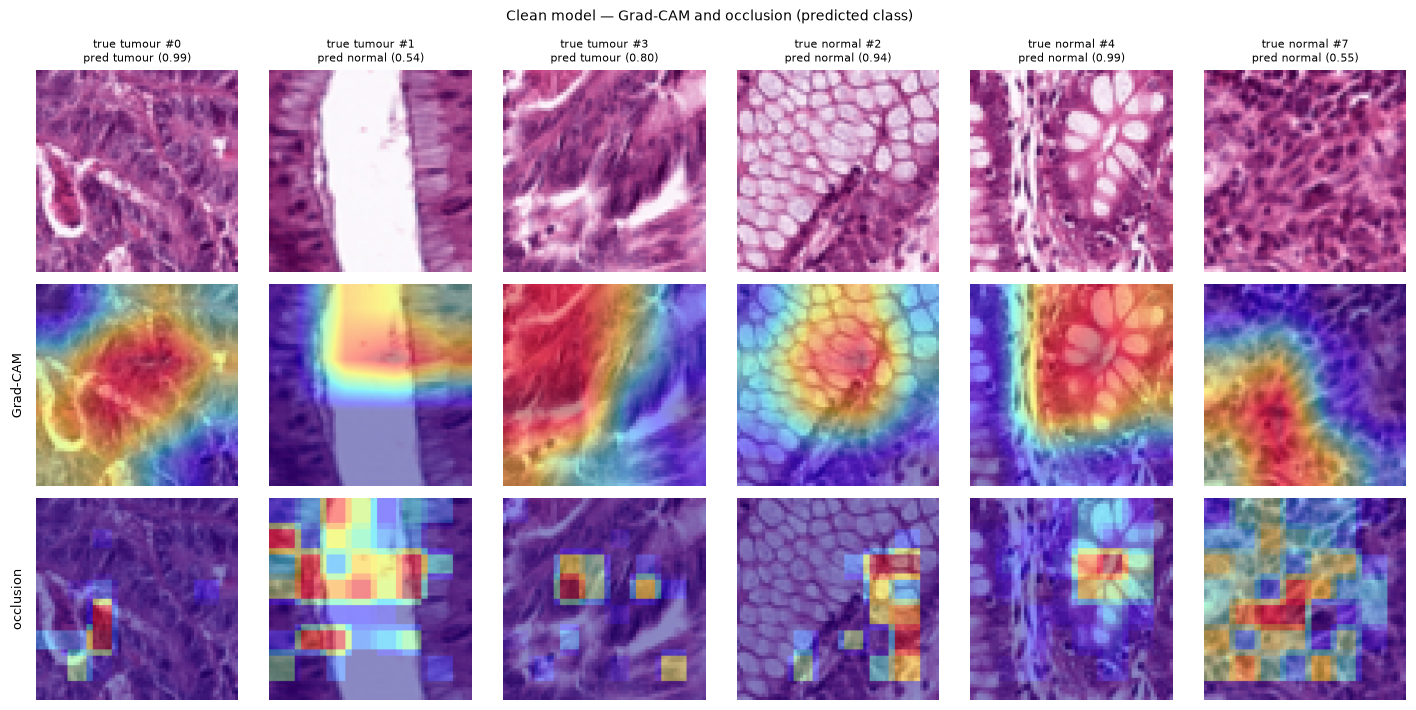

,tile,pred,p(pred),gradcam~occlusion r
0,true tumour #0,tumour,0.992,0.26
1,true tumour #1,normal,0.536,0.40
2,true tumour #3,tumour,0.798,0.12
3,true normal #2,normal,0.936,0.04
4,true normal #4,normal,0.992,0.61
5,true normal #7,normal,0.546,0.43


In [8]:
# NEW: Grad-CAM + occlusion on 3 tumour AND 3 normal test tiles
# (Notebook 2 showed Grad-CAM on 4 tumour tiles only, with no occlusion on the clean model).
cam = make_cam(model)
N_PROBE = 3
probe_tum = list(np.where(yte_s == 1)[0][:N_PROBE])
probe_nor = list(np.where(yte_s == 0)[0][:N_PROBE])
probe_idx = probe_tum + probe_nor

probe_df = probe_panel(model, cam,
                       [to01(xte_s[j]) for j in probe_idx],
                       [f"true {class_names[yte_s[j]]} #{j}" for j in probe_idx],
                       "Clean model — Grad-CAM and occlusion (predicted class)")
probe_df

### Checklist point 2: does the heat move when the target class changes?

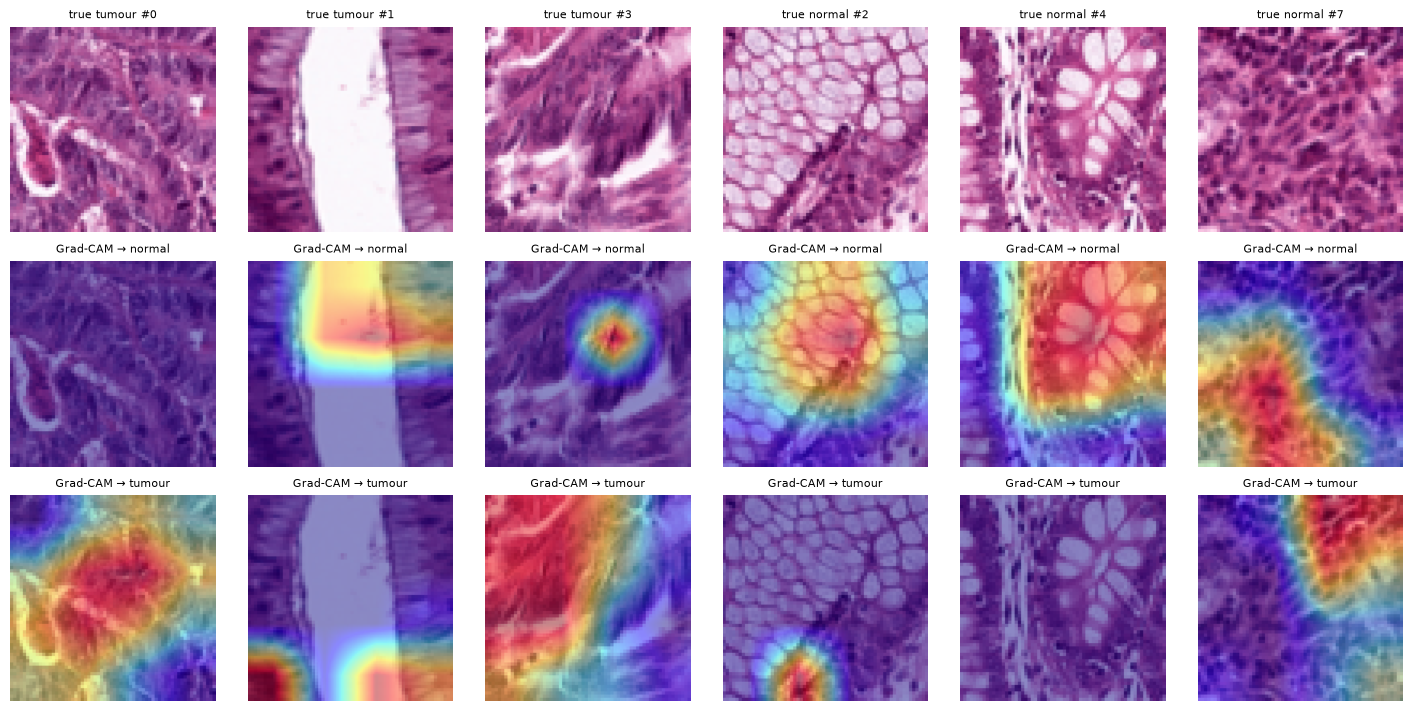

In [9]:
# NEW: Grad-CAM for the "normal" class and the "tumour" class on the same tile.
# Notebook 2 listed this checklist point but had no code for it.
fig, ax = plt.subplots(3, len(probe_idx), figsize=(2.4 * len(probe_idx), 7.2))
for col, j in enumerate(probe_idx):
    x01 = to01(xte_s[j]); disp = x01.permute(1, 2, 0).numpy()
    ax[0, col].imshow(disp); ax[0, col].set_title(f"true {class_names[yte_s[j]]} #{j}", fontsize=8)
    for r, c in enumerate((0, 1), start=1):
        ax[r, col].imshow(disp); ax[r, col].imshow(gradcam_map(model, cam, x01, c), cmap="jet", alpha=0.45, vmin=0, vmax=1)
        ax[r, col].set_title(f"Grad-CAM → {class_names[c]}", fontsize=8)
    for r in range(3): ax[r, col].axis("off")
plt.tight_layout(); plt.show()

### Skeptic's checklist — clean model

1. **Heat on plausible morphology, or on background / border / artifact?**
   > The heat maps seem to be on plausible morphology for most of the samples, except tumor 1, which highlights the blank spot in the middle.
2. **Does it move sensibly when the target class changes?**
   > It does move sensibly when the target class changes. The areas that are highlighted change when the class being searched for is changed.
3. **Does occlusion agree with Grad-CAM?**
   > Occlusion agrees with Grad-CAM weakly, with correlations ranging from 0.04 to 0.61. The agreement therefore ranges from basically none to moderate, with most in the weak range. Both should be included to ensure a complete view going forward.
4. **Would the highlighted region survive a different stain, scanner, or site?**
   > It is likely the highlighted region would survive a different stain, scanner, or site, given it is highlighting plausible morphology, but it cannot be claimed for sure that this is the case without further testing.
5. **Would a model that never saw a suspected artifact react the same way? (control)**
   > A model that never saw a suspected artifact would not react the same way. This is shown in part D, where the model predictions barely changed when the blurred patch was added.

**Verdict — is the clean model keying on tissue or on something it shouldn't?**
> The clean model is keying on tissue, mostly. The model failed on tumor 1 because of the blank area in the image, but the model found the tissue for the other samples.

## Part C · Confounder: out-of-focus blur patch

**Justification — why this is a plausible real-world batch effect:**
> Sometimes microscopes can be out of focus in patches of the image, especially if there is some small amount of moisture on the lens. It is possible that this would be the case for an entire batch of samples that are from the same class, for example if they are being imaged one after another.

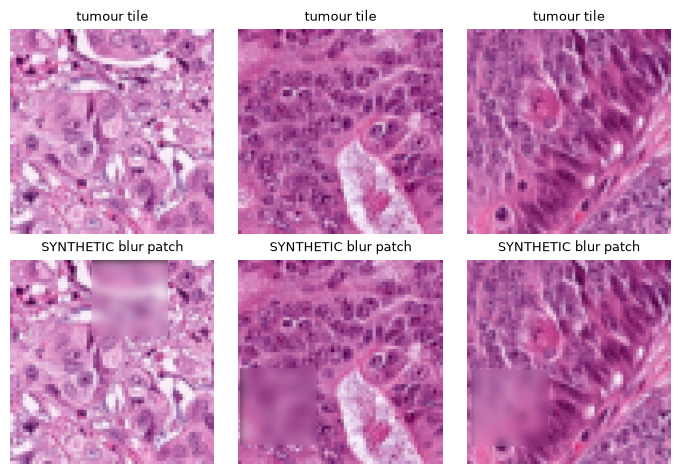

blur patch covers 14.1% of the tile (sigma = 3.0)


In [10]:
# NEW: the blur confounder (replaces Notebook 2's add_ink_mark / INK_MASK).
# A square region of the tile is Gaussian-blurred, like a local scanner focus failure.
# The position is random per tile but chosen from the tile's own pixels (a checksum seed),
# so the same tile always gets the same patch: runs are reproducible and both models
# are tested on identical blurred inputs.
ARTIFACT_LABEL = 1        # tumour
BLUR_SIZE = 48            # side of the blurred square in pixels (~14% of a 128 px tile)
BLUR_SIGMA = 3.0          # Gaussian standard deviation in pixels (larger = blurrier)

_smooth = GaussianSmooth(sigma=BLUR_SIGMA)

def blur_mask(x01):
    """Boolean (H, W) mask of where this tile's blur patch goes."""
    rng = np.random.default_rng(zlib.crc32(x01.numpy().tobytes()))
    top, left = rng.integers(0, IMG_SIZE - BLUR_SIZE + 1, size=2)
    m = torch.zeros(IMG_SIZE, IMG_SIZE, dtype=torch.bool)
    m[top:top + BLUR_SIZE, left:left + BLUR_SIZE] = True
    return m

def add_blur_patch(x01):
    m = blur_mask(x01)                      # mask from the CLEAN tile, so it's reproducible
    blurred = torch.as_tensor(_smooth(x01)) # blur the whole tile, then copy in only the patch
    out = x01.clone()
    out[:, m] = blurred[:, m]
    return out

# show the artifact on a few tumour tiles
js = np.where(ytr_s == 1)[0][:3]
fig, ax = plt.subplots(2, 3, figsize=(7, 4.8))
for k, j in enumerate(js):
    clean = to01(xtr_s[j]); dirty = add_blur_patch(clean)
    ax[0, k].imshow(clean.permute(1, 2, 0).numpy()); ax[0, k].set_title("tumour tile", fontsize=9)
    ax[1, k].imshow(dirty.permute(1, 2, 0).numpy()); ax[1, k].set_title("SYNTHETIC blur patch", fontsize=9)
    ax[0, k].axis("off"); ax[1, k].axis("off")
plt.tight_layout(); plt.show()
print(f"blur patch covers {BLUR_SIZE**2 / IMG_SIZE**2:.1%} of the tile (sigma = {BLUR_SIGMA})")

In [11]:
# Same training setup as Part A; every tumour tile (train AND val) now carries a blur patch.
set_determinism(seed=SEED)
tr_cf, va_cf = make_loaders(artifact_fn=add_blur_patch, artifact_label=ARTIFACT_LABEL)
print("Confounded model — every tumour tile (train and val) carries a blur patch:")
model_cf = train(build_densenet(pretrained=True), tr_cf, va_cf, epochs=EPOCHS)

# NEW: confounded vs. clean validation accuracy side by side.
cf_val_pred = predict(model_cf, xva_s, yva_s, add_blur_patch, ARTIFACT_LABEL)
cf_val_acc = (cf_val_pred == yva_s).mean()
print(f"\nconfounded model  validation accuracy (blurred tumour val tiles): {cf_val_acc:.3f}")
print(f"clean model       validation accuracy (no blur)                 : {clean_val_acc:.3f}")

Confounded model — every tumour tile (train and val) carries a blur patch:
  epoch 1: train loss 0.287 acc 0.887 | val loss 0.072 acc 0.990
  epoch 2: train loss 0.027 acc 1.000 | val loss 0.032 acc 0.995
  epoch 3: train loss 0.010 acc 1.000 | val loss 0.020 acc 0.998

confounded model  validation accuracy (blurred tumour val tiles): 0.998
clean model       validation accuracy (no blur)                 : 0.968


## Part D · Was the shortcut learned?

### D1 · Grad-CAM and occlusion on a blurred tumour tile — confounded vs. clean

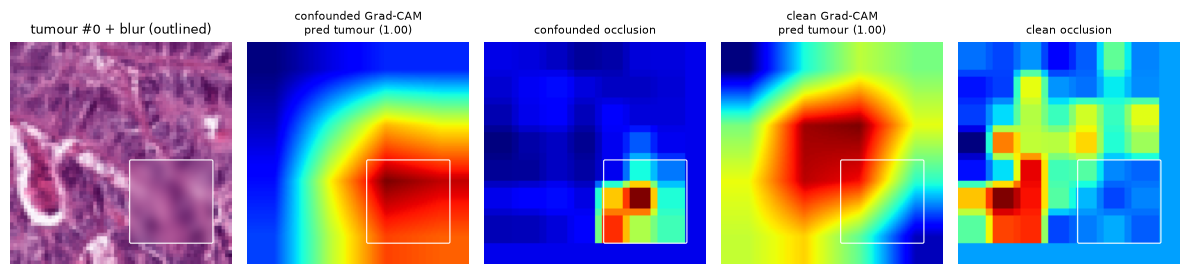

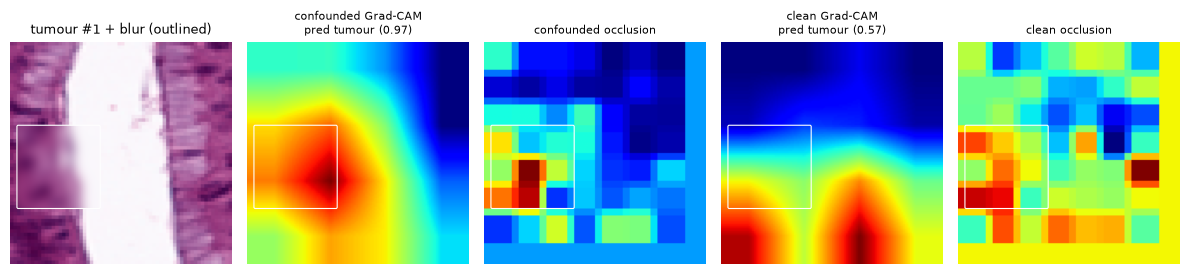

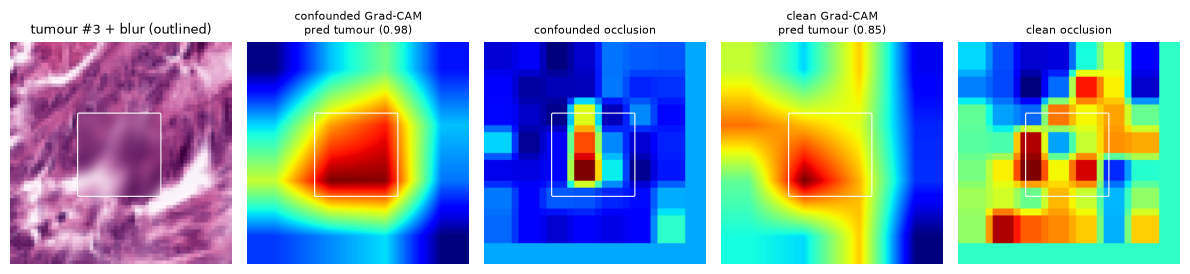

blur patch area share of the tile: 0.141  (a map with no preference would put ~this much evidence on the patch)


,tile,model,pred,p(tumour),Grad-CAM share on blur,occlusion share on blur
0,0,confounded,tumour,0.998,0.271,0.866
1,0,clean,tumour,0.998,0.129,0.017
2,1,confounded,tumour,0.968,0.226,0.593
3,1,clean,tumour,0.573,0.165,0.420
4,3,confounded,tumour,0.985,0.283,0.846
5,3,clean,tumour,0.849,0.216,0.285


In [12]:
cam_cf = make_cam(model_cf)

# CHANGED: Notebook 2's ink_share(), but takes the mask as an argument, because the
# blur patch is in a different place on every tile.
def artifact_share(m, mask):
    m = np.clip(m, 0, None)
    return m[mask].sum() / (m.sum() + 1e-8)

# NEW: Notebook 2 ran this on 1 tile with the confounded model only. This runs 3 tiles,
# BOTH models side by side (the clean model is the control), and tabulates the share of
# each map's evidence that falls on the blur patch.
D1_TILES = list(np.where(yte_s == 1)[0][:3])
d1_rows = []
for jt in D1_TILES:
    clean01 = to01(xte_s[jt])
    mask = blur_mask(clean01).numpy()
    x01 = add_blur_patch(clean01)
    fig, ax = plt.subplots(1, 5, figsize=(12, 2.8))
    ax[0].imshow(x01.permute(1, 2, 0).numpy()); ax[0].contour(mask, levels=[0.5], colors="white", linewidths=0.8)
    ax[0].set_title(f"tumour #{jt} + blur (outlined)", fontsize=9)
    for k, (name, net, co) in enumerate([("confounded", model_cf, cam_cf), ("clean", model, cam)]):
        pr, p = predict_one(net, x01)
        g = gradcam_map(net, co, x01, 1)
        o = occlusion_map(net, x01, target=1)
        ax[1 + 2*k].imshow(g, cmap="jet", vmin=0, vmax=1); ax[1 + 2*k].set_title(f"{name} Grad-CAM\npred {class_names[pr]} ({p[pr]:.2f})", fontsize=8)
        ax[2 + 2*k].imshow(o, cmap="jet"); ax[2 + 2*k].set_title(f"{name} occlusion", fontsize=8)
        for a in (ax[1 + 2*k], ax[2 + 2*k]):
            a.contour(mask, levels=[0.5], colors="white", linewidths=0.8)
        d1_rows.append({"tile": jt, "model": name, "pred": class_names[pr], "p(tumour)": round(float(p[1]), 3),
                        "Grad-CAM share on blur": round(artifact_share(g, mask), 3),
                        "occlusion share on blur": round(artifact_share(o, mask), 3)})
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()

print(f"blur patch area share of the tile: {BLUR_SIZE**2 / IMG_SIZE**2:.3f}  (a map with no preference would put ~this much evidence on the patch)")
d1_df = pd.DataFrame(d1_rows)
d1_df

### D2 · Reliance test — tumour recall with the blur vs. with it removed

In [13]:
# CHANGED: Notebook 2's tumour_acc(), batched through predict() instead of a per-tile loop,
# and run on BOTH models (Notebook 2 ran it on the confounded model only).
def tumour_recall(net, with_artifact):
    ti = np.where(yte_s == 1)[0]
    preds = predict(net, xte_s[ti], yte_s[ti], add_blur_patch if with_artifact else None, ARTIFACT_LABEL)
    return (preds == 1).mean()

rel = {name: (tumour_recall(net, True), tumour_recall(net, False))
       for name, net in [("confounded", model_cf), ("clean", model)]}
for name, (w, wo) in rel.items():
    print(f"{name:>10} model — tumour recall WITH blur: {w:.3f} | WITHOUT blur: {wo:.3f} | drop: {w - wo:+.3f}")

confounded model — tumour recall WITH blur: 0.997 | WITHOUT blur: 0.693 | drop: +0.303
     clean model — tumour recall WITH blur: 0.943 | WITHOUT blur: 0.937 | drop: +0.007


### D3 · Flip rate — blur added to normal tiles

In [14]:
# CHANGED: Notebook 2's normal_flip_rate(), batched through predict(). Also returns a second,
# stricter number (NEW): among normal tiles the model called normal WITHOUT the blur, the
# fraction that flip to tumour WITH it. (Notebook 2's single-tile flip demo is removed.)
def normal_flip_rate(net):
    ni = np.where(yte_s == 0)[0]
    base = predict(net, xte_s[ni], yte_s[ni])
    blurred = predict(net, xte_s[ni], yte_s[ni], add_blur_patch, 0)   # blur every normal tile
    flipped = ((base == 0) & (blurred == 1)).sum() / max((base == 0).sum(), 1)
    return (blurred == 1).mean(), flipped

flip = {name: normal_flip_rate(net) for name, net in [("confounded", model_cf), ("clean", model)]}
print(f"normal test tiles with the blur added: {(yte_s == 0).sum()}")
for name, (called, flipped) in flip.items():
    print(f"{name:>10} model — called tumour: {called:.1%} | flipped normal→tumour (of those called normal unblurred): {flipped:.1%}")

normal test tiles with the blur added: 300
confounded model — called tumour: 53.7% | flipped normal→tumour (of those called normal unblurred): 53.4%
     clean model — called tumour: 6.7% | flipped normal→tumour (of those called normal unblurred): 3.5%


### D4 · Clean control — summary

In [15]:
# NEW: every Part D number for both models in one table, plus the gap between them.
summary = pd.DataFrame({
    "clean model (control)": {
        "validation accuracy": clean_val_acc,
        "test accuracy (no blur)": clean_test_acc,
        "tumour recall WITH blur": rel["clean"][0],
        "tumour recall WITHOUT blur": rel["clean"][1],
        "normal tiles called tumour when blurred": flip["clean"][0],
        "normal→tumour flip rate": flip["clean"][1],
        "mean Grad-CAM share on blur (D1)": d1_df.query("model == 'clean'")["Grad-CAM share on blur"].mean(),
        "mean occlusion share on blur (D1)": d1_df.query("model == 'clean'")["occlusion share on blur"].mean(),
    },
    "confounded model": {
        "validation accuracy": cf_val_acc,
        "test accuracy (no blur)": (predict(model_cf, xte_s, yte_s) == yte_s).mean(),
        "tumour recall WITH blur": rel["confounded"][0],
        "tumour recall WITHOUT blur": rel["confounded"][1],
        "normal tiles called tumour when blurred": flip["confounded"][0],
        "normal→tumour flip rate": flip["confounded"][1],
        "mean Grad-CAM share on blur (D1)": d1_df.query("model == 'confounded'")["Grad-CAM share on blur"].mean(),
        "mean occlusion share on blur (D1)": d1_df.query("model == 'confounded'")["occlusion share on blur"].mean(),
    },
})
summary["gap (confounded − clean)"] = summary["confounded model"] - summary["clean model (control)"]
summary.round(3)

,clean model (control),confounded model,gap (confounded − clean)
validation accuracy,0.968,0.998,0.030
test accuracy (no blur),0.948,0.843,-0.105
tumour recall WITH blur,0.943,0.997,0.053
tumour recall WITHOUT blur,0.937,0.693,-0.243
normal tiles called tumour when blurred,0.067,0.537,0.470
normal→tumour flip rate,0.035,0.534,0.499
mean Grad-CAM share on blur (D1),0.170,0.260,0.090
mean occlusion share on blur (D1),0.241,0.768,0.528


### Interpretation

**Where does the heat land (D1)?**
> The heat lands mostly on the blurred regions for the confounded model for the occlusion evidence. A similar trend was found for the Grad-CAM evidence, where more of the heat lands on the blurred regions, but it was much less pronounced.

**Reliance test (D2):**
> The confounded model partially relies on the blur, shown in its drop of 0.3. It doesn't drop entirely, only by about a third, meaning the model does still look at other parts of the image, but it certainly relies on the blurred area partially.

**Flip rate (D3):**
> The flip rate for the confounded model was 53.4%, which indicates it sees the blurred area and uses it to classify tumors. The clean model had a flip rate of just 3.5%, showing it is much less affected by the addition of the blurred region.

**Clean control and verdict (D4) — was the shortcut learned, and how do you know?**
> The shortcut was learned by the confounded model, but it did not rely on it entirely. The reliance test showed it was partially reliant, the heat test showed it focused more on the blurred region, and the flip test showed it used the confounding factor as an important factor in prediction. The clean model mostly ignored the blurred regions, indicating the learned behavior of the confounded model.